In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [10]:
# Constants
KELVIN_OFFSET = 273.15

An Ornstein-Ulenbeck process for our purposes is an SDE of the form:

$$dT_t = \kappa\big(\mu(t) - T_t\big)dt + \sigma(t)dW_t$$

where $\mu(t)$ is the long term average, $\sigma(t)$ is the volatity scale factor (which adjusts the variance for different times of the year) and $\kappa$, which is usually a constant mean reversion speed factor but I will probably make this a function of $t$ to more accurately model lingering warmer temperatures.

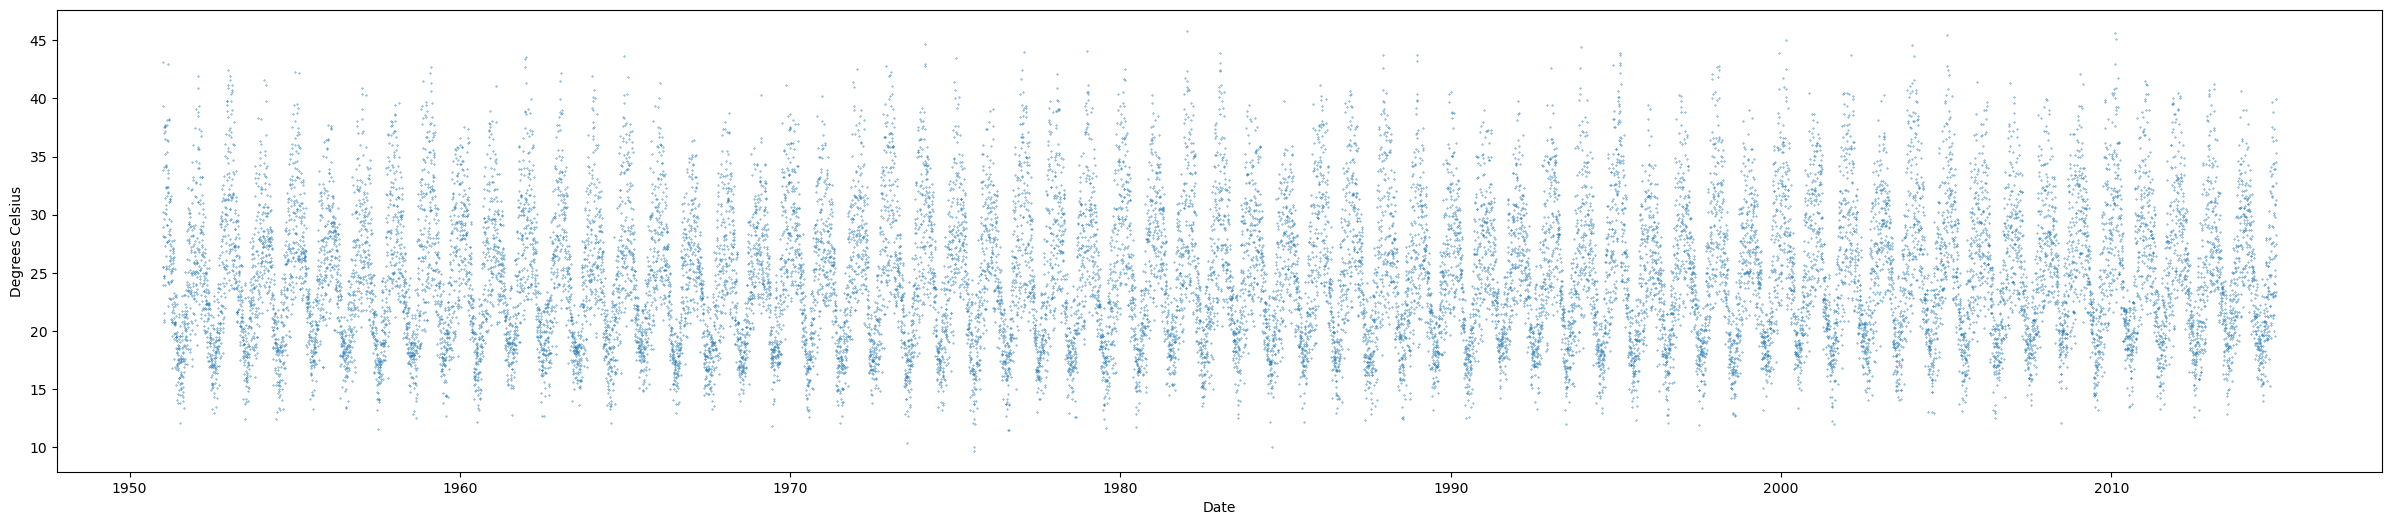

In [51]:
# Read historical daily maximum temperature data from Marsden Park, NSW
# Sourced from https://climatedata.environment.nsw.gov.au/narclim2-0/cmip6_dd_narclim2-0-seaus-04i_nsw-government_access-esm1-5_historical_r6i1p1f1_narclim2-0-wrf4157

df = pd.read_csv("historical_data.csv")

df["time"] = pd.to_datetime(df["time"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
df["Month"] = df["time"].dt.month
df["Day"]   = df["time"].dt.day
# Remove February 29
df = df[~((df["Month"] == 2) & (df["Day"] == 29))].copy()

plt.figure(figsize=(30,6))
plt.scatter(df["time"], df["tasmax"] - KELVIN_OFFSET, s=0.1)
plt.xlabel("Date")
plt.ylabel("Degrees Celsius")
plt.show()

We now aim to fit the historical data to a truncated Fourier series using Ordinary Least Squares to find $\mu(t)$, the average function.

$$a_1 + a_2t + a_3\sin \big(\frac{2\pi t}{365}\big) + a_4\cos \big(\frac{2\pi t}{365}\big) ...$$

This model will at least fit the seasonal temperature behaviour, however it will struggle to capture the extremes highs because the lows tend to be less extreme. I plan to account for this by finding a function for the mean regression factor in the Ornstein-Uhlenbeck SDE that causes the model to linger longer at higher temperatures. That is, I'll make $\kappa$ not a constant but a function of $t$.



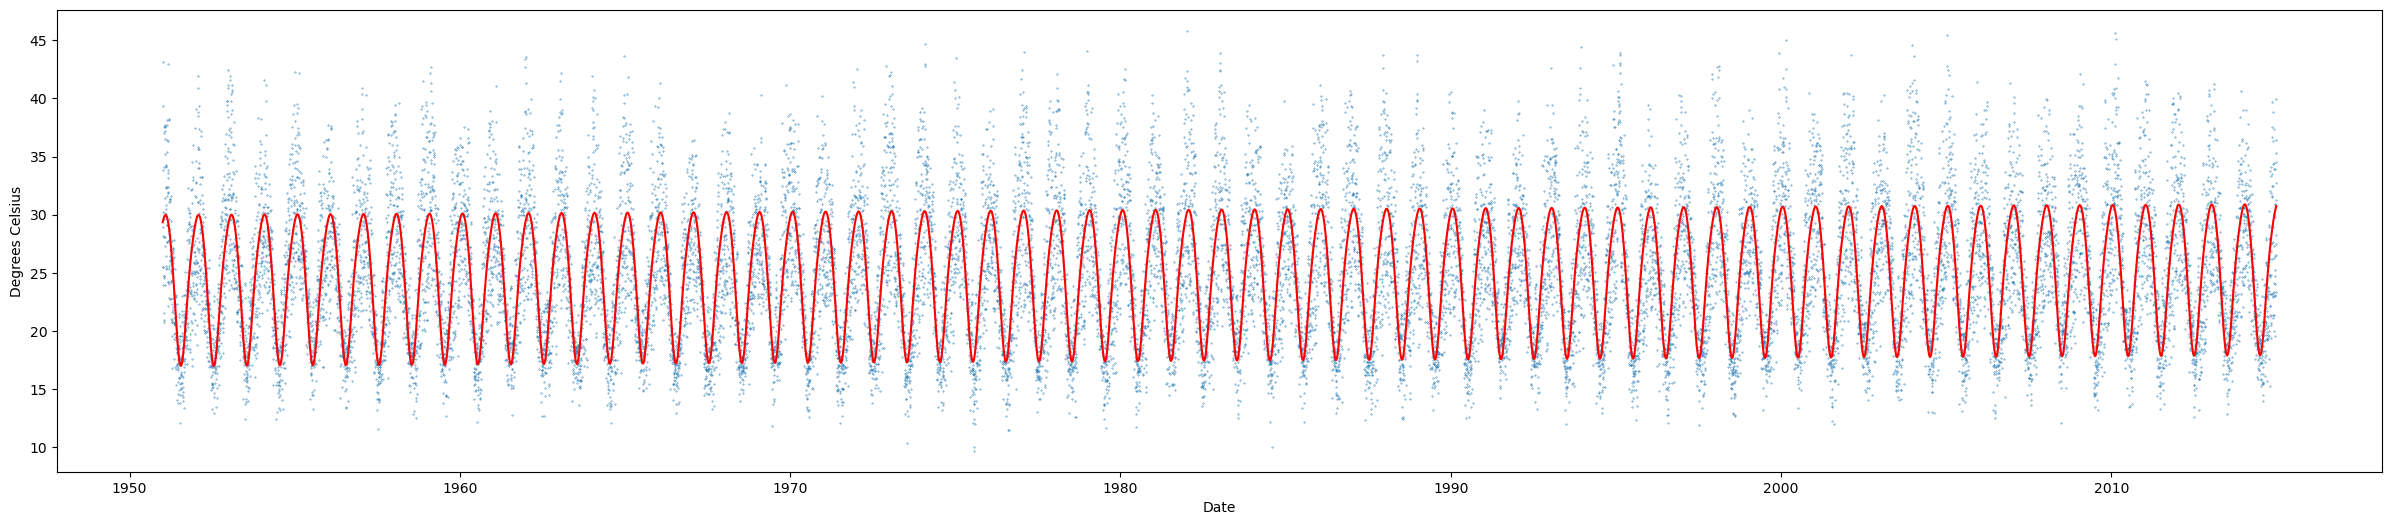

In [63]:
df["t"] = (df["time"] - df["time"].min()).dt.days.astype(float)
t = df["t"].to_numpy()
T = (df["tasmax"] - KELVIN_OFFSET).astype(float).to_numpy()

# Prepare truncated Fourier series model 
X = pd.DataFrame({
    "a_1": np.ones_like(t),
    "a_2": t,
    "a_3": np.sin(2 * np.pi * t / 365.0),
    "a_4": np.cos(2 * np.pi * t / 365.0),
    "a_5": np.sin(4 * np.pi * t / 365.0),
    "a_6": np.cos(4 * np.pi * t / 365.0),
    "a_7": np.sin(6 * np.pi * t / 365.0),
    "a_8": np.cos(6 * np.pi * t / 365.0),
})

model = sm.OLS(T, X).fit()
fitted_curve = model.predict(X)
coefficients = model.params.to_dict()

plt.figure(figsize=(30,6))
plt.scatter(df["time"], df["tasmax"] - KELVIN_OFFSET, s=0.1)
plt.plot(df["time"], fitted_curve, color="red")
plt.xlabel("Date")
plt.ylabel("Degrees Celsius")
plt.show()


Now that we have $\mu(t)$, we need to fit the volatility factor $\sigma(t)$. To do this, we measure the the daily variance.